Urządzenie: cpu
Architektura: (128,)
Epoka 1/3  Accuracy: 83.72%
Epoka 2/3  Accuracy: 84.05%
Epoka 3/3  Accuracy: 85.16%
Architektura: (256, 128)
Epoka 1/3  Accuracy: 84.46%
Epoka 2/3  Accuracy: 86.29%
Epoka 3/3  Accuracy: 86.81%
Architektura: (512, 256, 128)
Epoka 1/3  Accuracy: 84.25%
Epoka 2/3  Accuracy: 85.95%
Epoka 3/3  Accuracy: 87.23%
      Architektura  Parametry  Accuracy
0           (128,)     101770     85.16
1       (256, 128)     235146     86.81
2  (512, 256, 128)     567434     87.23


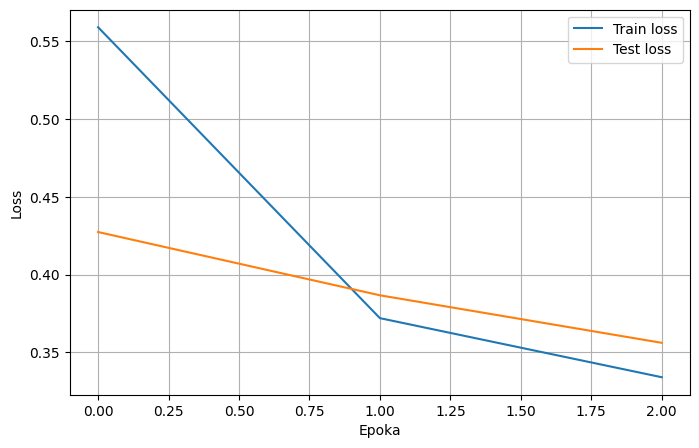

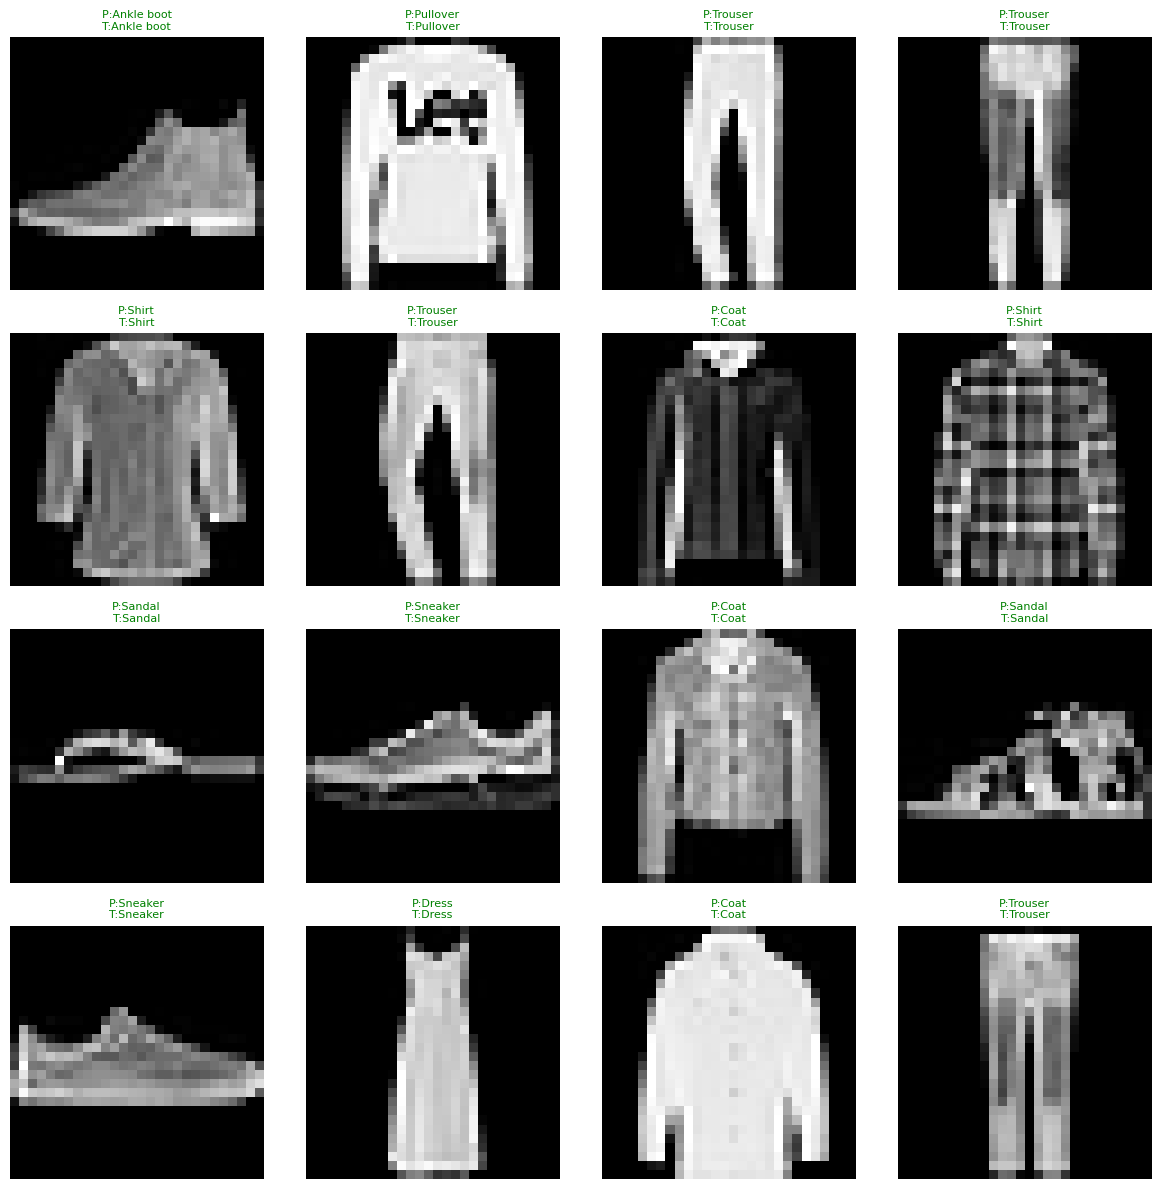

In [9]:


import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import pandas as pd

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Urządzenie:", device)


###FashionMNIST####


transform = transforms.ToTensor()

train_dataset = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)


###Def modelu###
class MLP(nn.Module):

    def __init__(self, input_size, hidden_layers, num_classes=10):

        super().__init__()

        layers = []

        prev = input_size

        for h in hidden_layers:
            layers.append(nn.Linear(prev, h))
            layers.append(nn.ReLU())
            prev = h

        layers.append(nn.Linear(prev, num_classes))

        self.net = nn.Sequential(*layers)

    def forward(self, x):
        x = x.view(x.size(0), -1)
        return self.net(x)

def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


###trenowanie modelu###
def train_model(model, epochs=3, lr=0.001):

    model.to(device)

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    train_losses = []
    test_losses = []

    best_acc = 0

    for epoch in range(epochs):

        model.train()

        running_loss = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

        train_losses.append(running_loss / len(train_loader))

        model.eval()

        running_loss = 0

        correct = 0
        total = 0

        with torch.no_grad():

            for images, labels in test_loader:

                images = images.to(device)
                labels = labels.to(device)

                outputs = model(images)

                loss = criterion(outputs, labels)

                running_loss += loss.item()

                _, predicted = torch.max(outputs, 1)

                total += labels.size(0)

                correct += (predicted == labels).sum().item()

        test_losses.append(running_loss / len(test_loader))

        accuracy = 100 * correct / total

        print(f"Epoka {epoch+1}/{epochs}  Accuracy: {accuracy:.2f}%")

        best_acc = accuracy

    return train_losses, test_losses, best_acc


###Teraz testujemy architektury#########
architectures = [
    (128,),
    (256,128),
    (512,256,128)
]

results = []

best_model = None
best_train_loss = None
best_test_loss = None
best_accuracy = 0

for arch in architectures:

    print("="*50)
    print("Architektura:", arch)

    model = MLP(28*28, arch)

    train_loss, test_loss, acc = train_model(model)

    params = count_parameters(model)

    results.append([str(arch), params, acc])

    if acc > best_accuracy:
        best_accuracy = acc
        best_model = model
        best_train_loss = train_loss
        best_test_loss = test_loss


#####tabela####
df = pd.DataFrame(
    results,
    columns=["Architektura", "Parametry", "Accuracy"]
)

print(df)


########WYKRES######
plt.figure(figsize=(8,5))

plt.plot(best_train_loss, label="Train loss")
plt.plot(best_test_loss, label="Test loss")

plt.xlabel("Epoka")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.show()

####PREDYKCJA###
classes = [
    "T-shirt",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

best_model.eval()

images, labels = next(iter(test_loader))

images = images.to(device)
labels = labels.to(device)

with torch.no_grad():
    outputs = best_model(images)

_, predicted = torch.max(outputs, 1)

plt.figure(figsize=(12,12))

for i in range(16):

    plt.subplot(4,4,i+1)

    plt.imshow(images[i].cpu().squeeze(), cmap="gray")

    color = "green" if predicted[i] == labels[i] else "red"

    plt.title(
        f"P:{classes[predicted[i]]}\nT:{classes[labels[i]]}",
        color=color,
        fontsize=8
    )

    plt.axis("off")

plt.tight_layout()
plt.show()